#### EDA on Netflix Data Understand content trends by year, genre, and country.

In [3]:

import pandas as pd
import matplotlib.pyplot as plt



df = pd.read_csv("Task/netflix_titles.csv")
print(df)


     show_id     type                  title         director  \
0         s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1         s2  TV Show          Blood & Water              NaN   
2         s3  TV Show              Ganglands  Julien Leclercq   
3         s4  TV Show  Jailbirds New Orleans              NaN   
4         s5  TV Show           Kota Factory              NaN   
...      ...      ...                    ...              ...   
8802   s8803    Movie                 Zodiac    David Fincher   
8803   s8804  TV Show            Zombie Dumb              NaN   
8804   s8805    Movie             Zombieland  Ruben Fleischer   
8805   s8806    Movie                   Zoom     Peter Hewitt   
8806   s8807    Movie                 Zubaan      Mozez Singh   

                                                   cast        country  \
0                                                   NaN  United States   
1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa 

In [4]:
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB
None


In [6]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64



Movies vs TV Shows:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


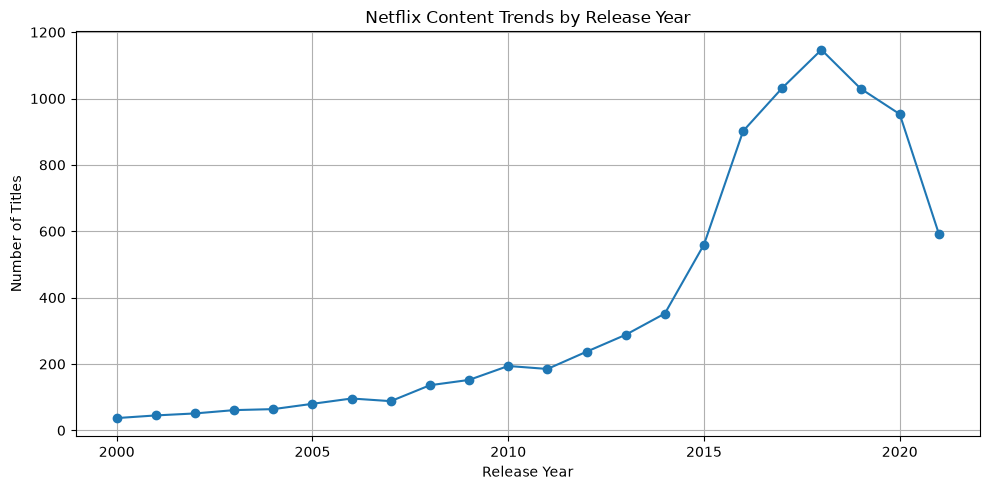

In [7]:
year_counts = df["release_year"].value_counts().sort_index()
year_counts = year_counts[year_counts.index >= 2000]
print("\nMovies vs TV Shows:")
print(df["type"].value_counts())

plt.figure(figsize=(10, 5))
year_counts.plot(kind="line", marker="o")
plt.title("Netflix Content Trends by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

### Statement
Movies have the highest count with 6,131 titles, followed by TV Shows with 2,676 titles. Movies account for 69.6% of the total content, while TV Shows account for 30.4%. Overall, the dataset contains significantly more movies than TV shows.


Top genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


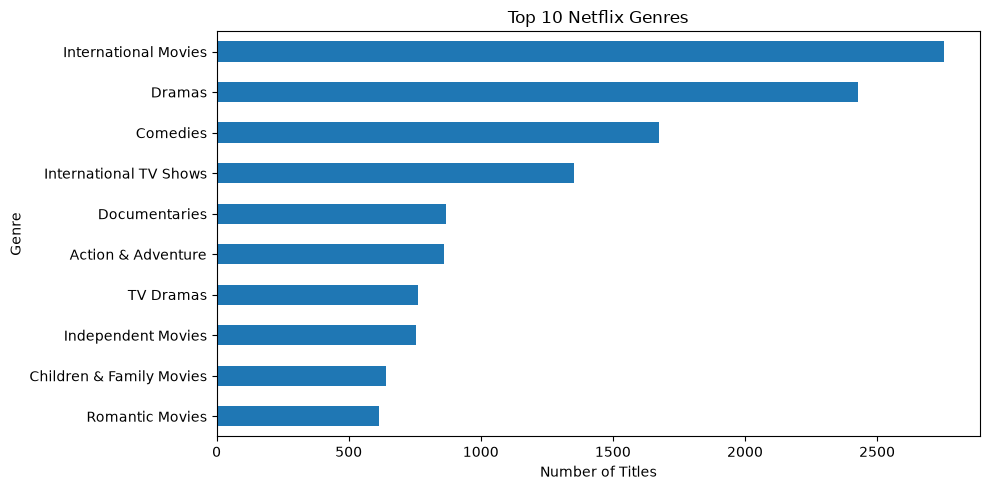

In [12]:
genres = df["listed_in"].dropna().str.split(", ").explode()
top_genres = genres.value_counts().head(10)
print("\nTop genres:")
print(top_genres)

plt.figure(figsize=(10, 5))
top_genres.sort_values().plot(kind="barh")
plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

### Statement
International Movies have the highest count with 2,752 titles, followed by Dramas (2,427) and Comedies (1,674). Romantic Movies have the lowest count among the top 10 genres, with 616 titles. Overall, international content and drama are the most common categories in the dataset.


Top countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


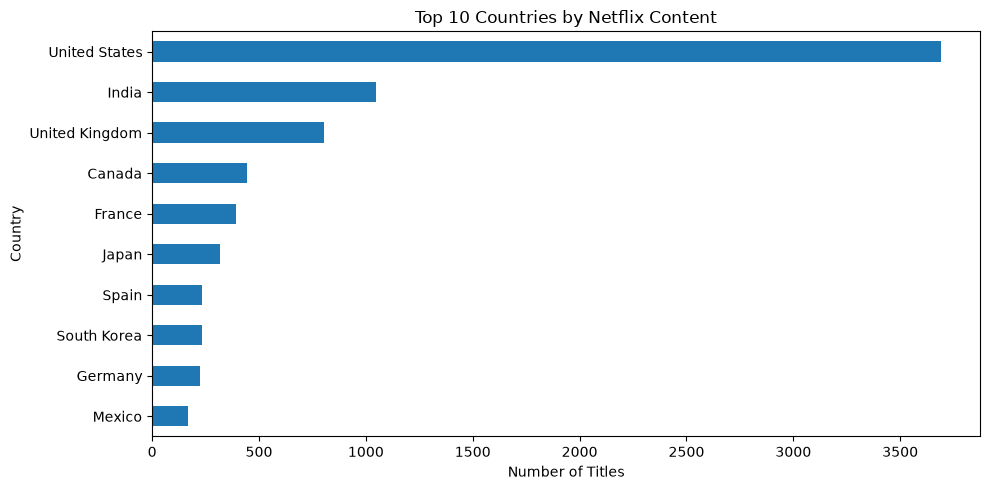

In [11]:
countries = df["country"].dropna().str.split(", ").explode()
top_countries = countries.value_counts().head(10)
print("\nTop countries:")
print(top_countries)

plt.figure(figsize=(10, 5))
top_countries.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Statement
The United States has the highest number of Netflix titles with 3,689, followed by India (1,046) and the United Kingdom (804). Mexico has the lowest count among the top 10 countries, with 169 titles. Overall, the United States contributes the largest share of content in the dataset.